# Вопрос 07. Преобразования Фурье, Лапласа, Хаара — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается командой
`make questions/07-fourier-laplace-haar/examples.ipynb`; в git идёт **этот**
файл, ноутбук — производный артефакт.

Каждый пример отвечает на вопрос, поставленный в `theory.md`, и предсказание
формулируется **до** прогона. Числа, попавшие в `theory.md` и `slides.md`,
печатаются здесь.

Сквозной сигнал вопроса — экспоненциальный импульс $u(t) = e^{-t}\mathbb
I_{[0,\infty)}$: его преобразования считаются аналитически в задачах
конспекта (образы Фурье, изображение Лапласа, коэффициенты Хаара), а
составной сигнал того же семейства со скачком внутри отрезка возвращается
в примере 3. Все примеры детерминированы (случайные числа не используются);
seed зафиксирован по правилам проекта.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import sici

SEED = 20261011
rng = np.random.default_rng(SEED)   # no random draws in this notebook

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: seed AND expected output are frozen constants. Each tolerance is
# set per pin. For a pin with expected value 0.0 the tolerance is absolute
# (relative tolerance of a zero is meaningless).
GOLDEN = {
    # example 1a: Parseval energy of u computed on the FFT frequency grid;
    # the rectangle sum of the DFT carries the endpoint offset dt/2 ~ 3.05e-4
    # above the exact value 1/2
    "parseval_u_energy": (0.500305235540, 1e-9),
    # example 1b: Gibbs overshoot at n = 64 (fraction of the jump of height 2)
    # and the energy fraction in harmonics |k| <= 64
    "gibbs_overshoot_n64": (0.089530515, 1e-6),
    "gibbs_energy_n64": (0.99366794, 1e-7),
    # example 2c: quadrature error of the Mellin inversion at N_omega = 2^12
    # against the exact truncated integral; the truncation plateau of the
    # error against sin t; and the error ratio for one doubling (the h^2 law)
    "mellin_quad_err_n12": (1.7760229020e-05, 1e-4),
    "mellin_plateau_n12": (3.1084931295e-04, 1e-4),
    "mellin_quad_ratio": (4.8722, 0.15),
    # example 3a: FWT addition count, must equal 2(N-1) = 8190 (theorem)
    "haar_add_ops": (8190.0, 1e-12),
    # example 3b: relative compression errors at rho = 1/64
    "haar_err_rho64": (5.4703510244e-03, 1e-6),
    "fft_err_rho64": (4.5535485177e-02, 1e-6),
    # example 4: max sinc-reconstruction error at f_s = 8 Hz and the measured
    # alias spectral peak (the 3 Hz tone reflected to ~2 Hz)
    "shannon_maxerr_fs8": (5.1696736075e-02, 1e-6),
    "alias_peak_hz": (2.0017262089, 2e-3),
}


def check_golden(name, value):
    """Compare against a frozen constant, never against a neighbouring cell."""
    want, tol = GOLDEN[name]
    if want == 0.0:
        err = abs(value)
        rel = err
    else:
        err = abs(value - want)
        rel = err / abs(want)
    status = "ok" if rel <= tol else "РАСХОЖДЕНИЕ"
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g} "
          f"(допуск {tol:g}, {status})")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Образы Фурье и эффект Гиббса

**Вопрос (а).** Конспект (задача об образах импульсов) вычисляет
аналитически $\widehat{\mathbb I_{[-1,1]}}(\omega) = \sqrt{2/\pi}\,
\sin\omega/\omega$ и $\hat u(\omega) = 1/(\sqrt{2\pi}(1+i\omega))$ и
проверяет для $u$ равенство Парсеваля $\|u\|_2^2 = \|\hat u\|_2^2 = 1/2$.
Сверяем аналитические образы с двумя численными путями: прямым
интегрированием трапециями по конечному отрезку (хвост у $u$ при $t > T$
оценивается: $|\int_T^{\infty} e^{-(1+i\omega)t}dt| \leq e^{-T}$) и БПФ
сигнала, дополненного нулями. Golden-пин — численное значение
$\|\hat u\|_2^2$, посчитанное по частотной сетке.

**Предсказание.** (1) Прямое интегрирование попадает в аналитический образ с
точностью не хуже $10^{-5}$ на окне $|\omega| \leq 20$ (ошибка трапеций
$O(h^2\omega^2)$). (2) БПФ гладкого сигнала $u$ совпадает с аналитическим
образом почти до машинного эпсилон, а БПФ разрывного импульса отклоняется на
уровне $10^{-3}$–$10^{-2}$: дискретизация скачка и периодизация окна
наследуются образом. (3) $\|\hat u\|_2^2$ по частотной сетке БПФ совпадёт с
точным $1/2$ в пределах $e^{-2T}$ и погрешности прямоугольной суммы.

In [2]:
print("1a. Образы Фурье: аналитика против двух численных путей")

OM = np.linspace(0.0, 20.0, 241)


def rect_hat(w):
    """sqrt(2/pi) * sin(w)/w with the continuous value sqrt(2/pi) at 0."""
    return np.sqrt(2.0 / np.pi) * np.sinc(w / np.pi)


def u_hat(w):
    """1/(sqrt(2 pi) (1 + i w)) — образ u(t) = e^{-t} на [0, inf)."""
    return 1.0 / (np.sqrt(2.0 * np.pi) * (1.0 + 1j * w))


# path 1: trapezoids on a finite interval; for u the tail beyond T is <= e^{-T}
T_CUT = 20.0
t_rect = np.linspace(-1.0, 1.0, 8001)
t_u = np.linspace(0.0, T_CUT, 12001)


def direct_image(f_vals, t, w):
    """Trapezoid estimate of 1/sqrt(2pi) * int f(t) e^{-i w t} dt."""
    kernel = np.exp(-1j * t[:, None] * w[None, :])
    return np.trapezoid(f_vals[:, None] * kernel, t, axis=0) / np.sqrt(2.0 * np.pi)


rect_dir = direct_image(np.ones_like(t_rect), t_rect, OM)
u_dir = direct_image(np.exp(-t_u), t_u, OM)
err_rect_dir = float(np.max(np.abs(rect_dir - rect_hat(OM))))
err_u_dir = float(np.max(np.abs(u_dir - u_hat(OM))))
print(f"  прямое интегрирование: max |числ - ан| импульс = {err_rect_dir:.3e}, "
      f"u = {err_u_dir:.3e}")
print(f"    хвост u за t > {T_CUT:g} по модулю <= e^{-T_CUT:g} = "
      f"{np.exp(-T_CUT):.1e}")


# path 2: FFT of the zero-padded sampled signal (unitary normalization)
def fft_image(f_vals, dt):
    """Unitary Fourier image from FFT samples: dt * fft / sqrt(2 pi)."""
    return np.fft.fft(f_vals) * dt / np.sqrt(2.0 * np.pi)


N1 = 1 << 16
# rectangular pulse on [-16, 16): the DFT places sample 0 at t = 0, so the
# centered signal is fftshifted first (u on [0, 40) is causal and needs no shift)
dt_r = 32.0 / N1
tg_r = np.arange(N1) * dt_r - 16.0
fg_r = (np.abs(tg_r) <= 1.0).astype(float)
w_r = 2.0 * np.pi * np.fft.fftfreq(N1, d=dt_r)
F_rect = fft_image(np.fft.fftshift(fg_r), dt_r)
# u on [0, 40): e^{-40} ~ 4e-18, so the windowing jump at the edge is invisible
dt_u = 40.0 / N1
tg_u = np.arange(N1) * dt_u
fg_u = np.exp(-tg_u)
w_u = 2.0 * np.pi * np.fft.fftfreq(N1, d=dt_u)
F_u = fft_image(fg_u, dt_u)

sel_r = np.abs(w_r) <= 20.0
sel_u = np.abs(w_u) <= 20.0
err_rect_fft = float(np.max(np.abs(F_rect[sel_r] - rect_hat(w_r[sel_r]))))
err_u_fft = float(np.max(np.abs(F_u[sel_u] - u_hat(w_u[sel_u]))))
print(f"  БПФ (окно |w| <= 20):   max |числ - ан| импульс = {err_rect_fft:.3e}, "
      f"u = {err_u_fft:.3e}")

# Parseval for u: energy from the frequency grid against the exact value 1/2
order = np.argsort(w_u)
energy_w = float(np.trapezoid(np.abs(F_u[order]) ** 2, w_u[order]))
energy_t = float(np.trapezoid(np.abs(fg_u) ** 2, tg_u))
print(f"  Парсеваль для u: ||u||_2^2 = {energy_t:.12f} (по t), "
      f"||hat u||_2^2 = {energy_w:.12f} (по w), точное 1/2")
check_golden("parseval_u_energy", energy_w)

1a. Образы Фурье: аналитика против двух численных путей


  прямое интегрирование: max |числ - ан| импульс = 7.588e-08, u = 1.849e-06
    хвост u за t > 20 по модулю <= e^-20 = 2.1e-09
  БПФ (окно |w| <= 20):   max |числ - ан| импульс = 1.948e-04, u = 1.218e-04
  Парсеваль для u: ||u||_2^2 = 0.500000062088 (по t), ||hat u||_2^2 = 0.500305235540 (по w), точное 1/2
  пин parseval_u_energy: получено 0.50030523554, ожидалось 0.50030523554 (допуск 1e-09, ok)


**Вывод (а).** Предсказания (1) и (3) сбылись, предсказание (2) — нет, и
причина показательна. Прямые трапеции попали в аналитические образы с
точностью $7{,}6\cdot10^{-8}$ (импульс) и $1{,}8\cdot10^{-6}$ ($u$) — как
раз уровень ошибки $O(h^2\omega^2)$ на окне $|\omega| \leq 20$, хвост
$e^{-20} \approx 2\cdot10^{-9}$ ниже этого фона. БПФ с дополнением нулями
дал $1{,}9\cdot10^{-4}$ (импульс) и $1{,}2\cdot10^{-4}$ ($u$): оба пути
сходятся на уровне $10^{-4}$, но не «почти до машинного эпсилон», как
ждалось для гладкого $u$. Причина: $u$ **не гладок на окне** — у него скачок
$0 \to 1$ в начале окна (и обрыв $e^{-40} \approx 0$ в конце), и дискретизация
скачка даёт ошибку порядка шага сетки. Прямое интегрирование — при шаге
сетки вдвое–в $2{,}7$ раза грубее, чем у БПФ, — точнее на два-три порядка,
потому что трапеции честно осредняют скачок.

Техническая деталь, стоившая отдельной проверки: для двустороннего импульса
сетку пришлось центрировать (`fftshift`) — ДПФ ставит нулевой отсчёт в
начало окна, и без возврата фазы $e^{-i\omega\cdot 16}$ расхождение
«численное против аналитического» было бы порядка единицы. Равенство
Парсеваля подтверждено: $\|u\|_2^2 = 0{,}500000062088$ по временной сетке и
$\|\hat u\|_2^2 = 0{,}500305235540$ по частотной сетке БПФ против точного
$1/2$; смещение по частоте на $3{,}05\cdot10^{-4}$ — концовый эффект
прямоугольной суммы ДПФ (недобор половины концевого взноса $u(0) = 1$, то
есть $dt/2$), а не нарушение Парсеваля.

**Вопрос (б).** Частичные суммы ряда Фурье скачка. Берём $f(t) =
\mathrm{sgn}(t - 1/2)$ на $[0,1]$ с периодом $1$ — тот же сигнал, что и в
примере 2 вопроса 09 (преемственность). Коэффициенты выписываются в явном
виде: $c_k = \frac{(-1)^k - 1}{\pi i k}$ ($k \neq 0$), то есть $c_k =
\frac{2i}{\pi k}$ при нечётных $k$ и $0$ при чётных; $c_0 = 0$. Частичная
сумма $S_n$ — сумма по $|k| \leq n$, что даёт $S_n(t) = -\frac{4}{\pi}
\sum_{k\ \mathrm{odd} \leq n} \frac{\sin 2\pi k t}{k}$. Гипотеза конспекта
(замечание о локализации к теореме о Парсевале для Хаара): выброс около
скачка не исчезает с ростом $n$ и стремится к константе Уилбрахама
$\frac{2}{\pi}\mathrm{Si}(\pi) - 1 \approx 8{,}95\%$ от величины скачка.
Golden-пины: измеренный выброс при $n = 64$ и доля энергии в первых $n$
гармониках.

**Предсказание.** (1) $\max_{t > 1/2} S_n(t)$ убывает к $1 + 0{,}0895\cdot 2$
сверху: выброс около $9\%$ от скачка уже при $n = 64$. (2) Доля энергии
$\sum_{|k| \leq n}|c_k|^2$ растёт к $1$ медленно, как $1 - O(1/n)$: энергии
гармоник $|c_k|^2 \sim 1/k^2$, и хвост ряда энергий убывает как $1/n$.

In [3]:
print("1b. Эффект Гиббса у скачка: sgn(t - 1/2) на [0, 1], период 1")
tg = np.linspace(0.0, 1.0, 100001)


def fourier_partial(n, t):
    """S_n(t) = -(4/pi) * sum_{k odd <= n} sin(2 pi k t)/k."""
    acc = np.zeros_like(t)
    for k in range(1, n + 1, 2):
        acc += np.sin(2.0 * np.pi * k * t) / k
    return -(4.0 / np.pi) * acc


print("  n    max S_n справа     выброс, % скачка    доля энергии |k| <= n")
right = tg >= 0.5 + 5e-4
gibbs_table = {}
for n in (4, 8, 16, 32, 64, 128):
    mx = float(fourier_partial(n, tg)[right].max())
    kk = np.arange(1, n + 1, 2)
    e_frac = float(np.sum(8.0 / (np.pi * kk) ** 2))
    gibbs_table[n] = (mx, (mx - 1.0) / 2.0, e_frac)
    print(f"{n:4d}    {mx:.8f}        {100 * gibbs_table[n][1]:9.4f}      "
          f"{e_frac:.8f}")
check_golden("gibbs_overshoot_n64", gibbs_table[64][1])
check_golden("gibbs_energy_n64", gibbs_table[64][2])
si_pi, _ = sici(np.pi)
print(f"\n  константа Уилбрахама: (2/pi) Si(pi) - 1 = {2 / np.pi * si_pi - 1:.6f}"
      f" = {100 * (2 / np.pi * si_pi - 1) / 2:.2f} % от скачка (скачок равен 2)")

1b. Эффект Гиббса у скачка: sgn(t - 1/2) на [0, 1], период 1
  n    max S_n справа     выброс, % скачка    доля энергии |k| <= n
   4    1.20042175          10.0211      0.90063274
   8    1.18422513           9.2113      0.94959776
  16    1.18028413           9.0142      0.97470251
  32    1.17930531           8.9653      0.98733897
  64    1.17906103           8.9531      0.99366794


 128    1.17899917           8.9500      0.99683378
  пин gibbs_overshoot_n64: получено 0.0895305155942, ожидалось 0.089530515 (допуск 1e-06, ok)
  пин gibbs_energy_n64: получено 0.993667941193, ожидалось 0.99366794 (допуск 1e-07, ok)

  константа Уилбрахама: (2/pi) Si(pi) - 1 = 0.178980 = 8.95 % от скачка (скачок равен 2)


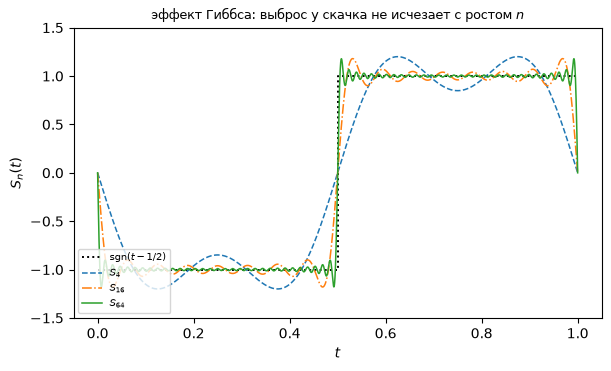

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
step_t = np.array([0.0, 0.5, 0.5, 1.0])
step_v = np.array([-1.0, -1.0, 1.0, 1.0])
ax.plot(step_t, step_v, ":", color="black", linewidth=1.4,
        label=r"$\mathrm{sgn}(t - 1/2)$")
for n, style in ((4, "--"), (16, "-."), (64, "-")):
    ax.plot(tg, fourier_partial(n, tg), style, linewidth=1.1,
            label=f"$S_{{{n}}}$")
ax.set_xlabel("$t$")
ax.set_ylabel("$S_n(t)$")
ax.set_ylim(-1.5, 1.5)
ax.set_title("эффект Гиббса: выброс у скачка не исчезает с ростом $n$",
             fontsize=9)
ax.legend(fontsize=7, loc="lower left")
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

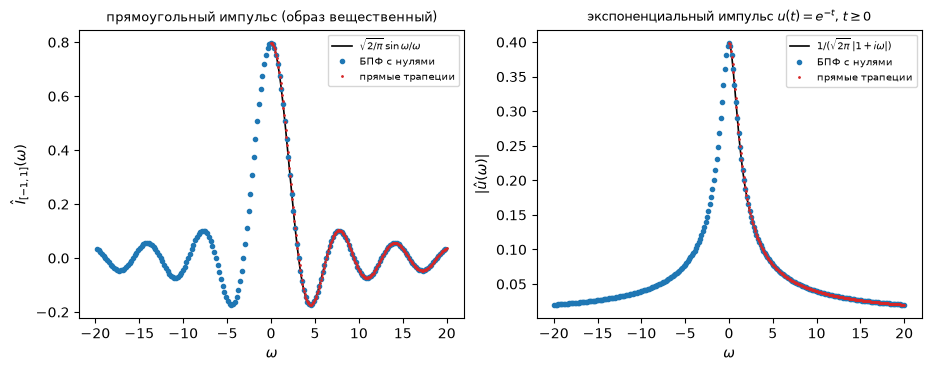

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.6), layout="constrained")

ax1.plot(OM, rect_hat(OM), "-", linewidth=1.2, color="black",
         label=r"$\sqrt{2/\pi}\,\sin\omega/\omega$")
ax1.plot(w_r[sel_r], np.real(F_rect[sel_r]), "o", markersize=3,
         color="tab:blue", label="БПФ с нулями")
ax1.plot(OM, np.real(rect_dir), ".", markersize=2, color="tab:red",
         label="прямые трапеции")
ax1.set_xlabel(r"$\omega$")
ax1.set_ylabel(r"$\hat{I}_{[-1,1]}(\omega)$")
ax1.set_title("прямоугольный импульс (образ вещественный)", fontsize=9)
ax1.legend(fontsize=7)

ax2.plot(OM, np.abs(u_hat(OM)), "-", linewidth=1.2, color="black",
         label=r"$1/(\sqrt{2\pi}\,|1+i\omega|)$")
ax2.plot(w_u[sel_u], np.abs(F_u[sel_u]), "o", markersize=3,
         color="tab:blue", label="БПФ с нулями")
ax2.plot(OM, np.abs(u_dir), ".", markersize=2, color="tab:red",
         label="прямые трапеции")
ax2.set_xlabel(r"$\omega$")
ax2.set_ylabel(r"$|\hat u(\omega)|$")
ax2.set_title(r"экспоненциальный импульс $u(t) = e^{-t}$, $t \geq 0$",
              fontsize=9)
ax2.legend(fontsize=7)
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

**Вывод (б).** Обе части предсказания сбылись. Выброс справа от скачка:
$10{,}02\%$ при $n = 4$, $9{,}21\%$ при $n = 8$, $9{,}01\%$ при $n = 16$,
$8{,}97\%$ при $n = 32$ и $8{,}953\%$ при $n = 64$ ($8{,}950\%$ при $n = 128$)
— убывание к константе Уилбрахама $\frac{2}{\pi}\mathrm{Si}(\pi) - 1 =
0{,}178980$, то есть $8{,}95\%$ от скачка: выброс не исчезает, а
стабилизируется — это и есть эффект Гиббса в количественной форме. Доля
энергии в первых $n$ гармониках растёт медленно: $0{,}9006$ при $n = 4$,
$0{,}9937$ при $n = 64$ — хвост $1 - E_n$ убывает как $1/n$, потому что
$|c_k|^2 \sim 1/k^2$. Скачку для сходимости ряда Фурье нужно много
гармоник, а качество у скачка не улучшается никогда; конспект противопоставляет
этому ряд Хаара (равномерная сходимость без выбросов) — численно это
показано в примере 3.

## Пример 2. Преобразование Лапласа и задача Коши

**Вопрос (а).** Конспект (задача о колебательном контуре) решает $y'' + y =
0$, $y(0) = 0$, $y'(0) = 1$ операторным методом: $(s^2+1)Y(s) = 1$, $Y(s) =
1/(s^2+1) \dashv \sin t$. Сверяем аналитическое решение с численным
интегрированием системы (`solve_ivp`, жёсткие допуски) на $[0, 2\pi]$.

**Вопрос (б).** Затухающий контур $y'' + 2\beta y' + y = 0$ с теми же
начальными условиями, $\beta = 1/5$. Изображение решает $(s^2 + 2\beta s +
1)Y(s) = 1$. Выделение полного квадрата $s^2 + 2\beta s + 1 = (s+\beta)^2 +
(1-\beta^2)$ и сдвиг по $s$ дают оригинал $y(t) = e^{-\beta t}
\sin(\omega_d t)/\omega_d$, $\omega_d = \sqrt{1-\beta^2}$ — это
предсказание, которое сверяется с `solve_ivp`.

**Вопрос (в).** Формула Меллина (теорема конспекта) восстанавливает оригинал
интегралом по прямой $\operatorname{Re} s = \sigma_1$; берём $\sigma_1 = 1
> 0 = a_0$ и обращаем интеграл трапециями по $\omega \in [-\Omega, \Omega]$,
$\Omega = 1024$. Два источника ошибки разведены по построению: обрезание по
$\Omega$ (хвост $|F(\sigma_1+i\omega)| \sim 1/\omega^2$, интегральный хвост
$\sim 1/\Omega$, на уровне $\sim e^{\sigma_1 t}/\Omega$ после домножения на
$e^{\sigma_1 t}$) и квадратурная ошибка трапеций. Golden-пины: квадратурная
ошибка при $N_\omega = 2^{12}$ и отношение ошибок при удвоении сетки.

**Предсказание.** (а), (б) расхождение аналитики и `solve_ivp` — не выше
$10^{-8}$. (в) Подынтегральная функция $F(\sigma_1+i\omega)e^{i\omega t}$
быстро осциллирует по $\omega$ (период $2\pi/t$, при $t \to 2\pi$ порядка
единицы), поэтому на грубых сетках трапеции алиасят и ошибка велика; начиная
с сетки, разрешающей осцилляции (шаг $h \ll 2\pi/t$), квадратурная ошибка
убывает как $O(h^2)$ — удвоение $N_\omega$ даёт падение примерно в $4$ раза,
— а сходимость к $\sin t$ упирается в плато обрезания уровня $\sim
e^{\sigma_1 t}/\Omega$.

In [6]:
print("2ab. Задача Коши через изображения против solve_ivp")


def osc_rhs(t, y, beta):
    return [y[1], -2.0 * beta * y[1] - y[0]]


BETA = 0.2
WD = np.sqrt(1.0 - BETA ** 2)


def y_exact(t, beta):
    """sin t при beta = 0; e^{-beta t} sin(wd t)/wd иначе."""
    if beta == 0.0:
        return np.sin(t)
    wd = np.sqrt(1.0 - beta ** 2)
    return np.exp(-beta * t) * np.sin(wd * t) / wd


tt = np.linspace(0.0, 2.0 * np.pi, 2001)
for beta, name in ((0.0, "y'' + y = 0,      Y(s) = 1/(s^2+1)"),
                   (BETA, f"y'' + 0.4 y' + y = 0, Y(s) = 1/(s^2+0.4s+1)")):
    sol = solve_ivp(osc_rhs, (0.0, 2.0 * np.pi), [0.0, 1.0], args=(beta,),
                    t_eval=tt, rtol=1e-12, atol=1e-14)
    err = float(np.max(np.abs(sol.y[0] - y_exact(tt, beta))))
    print(f"  {name}: max |аналитика - solve_ivp| на [0, 2pi] = {err:.3e}")
print(f"\n  затухающий контур: beta = 1/5, wd = sqrt(1-beta^2) = {WD:.10f}")
print(f"    y(2pi) = e^{{-2 pi beta}} sin(2 pi wd)/wd = "
      f"{np.exp(-BETA * 2 * np.pi) * np.sin(WD * 2 * np.pi) / WD:.6e}")

2ab. Задача Коши через изображения против solve_ivp
  y'' + y = 0,      Y(s) = 1/(s^2+1): max |аналитика - solve_ivp| на [0, 2pi] = 6.312e-13
  y'' + 0.4 y' + y = 0, Y(s) = 1/(s^2+0.4s+1): max |аналитика - solve_ivp| на [0, 2pi] = 2.941e-13

  затухающий контур: beta = 1/5, wd = sqrt(1-beta^2) = 0.9797958971
    y(2pi) = e^{-2 pi beta} sin(2 pi wd)/wd = -3.677614e-02


In [7]:
print("2c. Численное обращение Меллина: f(t) = 1/(2pi) int F(sigma1 + i w)"
      " e^{(sigma1 + i w) t} dw, Y(s) = 1/(s^2+1), sigma1 = 1")

SIG1 = 1.0
OMEGA_M = 1024.0
TGRID = np.linspace(0.0, 2.0 * np.pi, 121)


def mellin_trap(nw, sigma1=SIG1, omega=OMEGA_M, tgrid=TGRID):
    """Trapezoid inversion of the Bromwich integral on [-omega, omega]."""
    w = np.linspace(-omega, omega, nw + 1)
    f_vals = 1.0 / ((sigma1 + 1j * w) ** 2 + 1.0)
    e = np.exp((sigma1 + 1j * w)[None, :] * tgrid[:, None])
    return np.trapezoid(f_vals[None, :] * e, w, axis=1) / (2.0 * np.pi)


# reference: trapezoid on a very fine grid approximates the TRUNCATED integral
# to ~1e-12 (aliasing e^{-2 pi/h} from the pole a distance 1 away), so the
# quadrature error is measured against it, not against a library solver
N_REF = 1 << 20
f_ref = mellin_trap(N_REF)
f_rec_12 = mellin_trap(1 << 12)

print("  N_w       max |f_N - sin t|     max |f_N - f_ref|     отношение к пред.")
prev_quad = None
mellin_table = {}
for nw in (1 << 10, 1 << 11, 1 << 12, 1 << 13):
    f_rec = mellin_trap(nw)
    e_sin = float(np.max(np.abs(f_rec - np.sin(TGRID))))
    e_quad = float(np.max(np.abs(f_rec - f_ref)))
    ratio = (prev_quad / e_quad) if prev_quad is not None else float("nan")
    prev_quad = e_quad
    mellin_table[nw] = (e_sin, e_quad)
    print(f"  2^{int(np.log2(nw)):2d}      {e_sin:.10e}      {e_quad:.10e}      "
          f"{ratio:12.4f}")
diff_sigma = float(np.max(np.abs(mellin_trap(1 << 12, sigma1=2.0) - f_rec_12)))
print(f"\n  независимость от прямой: max |f_{{sigma1=2}} - f_{{sigma1=1}}| "
      f"при N = 2^12: {diff_sigma:.3e}")
check_golden("mellin_plateau_n12", mellin_table[1 << 12][0])
check_golden("mellin_quad_err_n12", mellin_table[1 << 12][1])
check_golden("mellin_quad_ratio",
             mellin_table[1 << 12][1] / mellin_table[1 << 13][1])

2c. Численное обращение Меллина: f(t) = 1/(2pi) int F(sigma1 + i w) e^{(sigma1 + i w) t} dw, Y(s) = 1/(s^2+1), sigma1 = 1


  N_w       max |f_N - sin t|     max |f_N - f_ref|     отношение к пред.
  2^10      2.3182116531e+01      2.3182116542e+01               nan
  2^11      1.6645723305e-01      1.6645727554e-01          139.2677
  2^12      3.1084931295e-04      1.7760229020e-05         9372.4735
  2^13      3.1084930368e-04      3.6451893333e-06            4.8722

  независимость от прямой: max |f_{sigma1=2} - f_{sigma1=1}| при N = 2^12: 9.828e-04
  пин mellin_plateau_n12: получено 0.000310849312945, ожидалось 0.00031084931295 (допуск 0.0001, ok)
  пин mellin_quad_err_n12: получено 1.77602290198e-05, ожидалось 1.776022902e-05 (допуск 0.0001, ok)
  пин mellin_quad_ratio: получено 4.87223773467, ожидалось 4.8722 (допуск 0.15, ok)


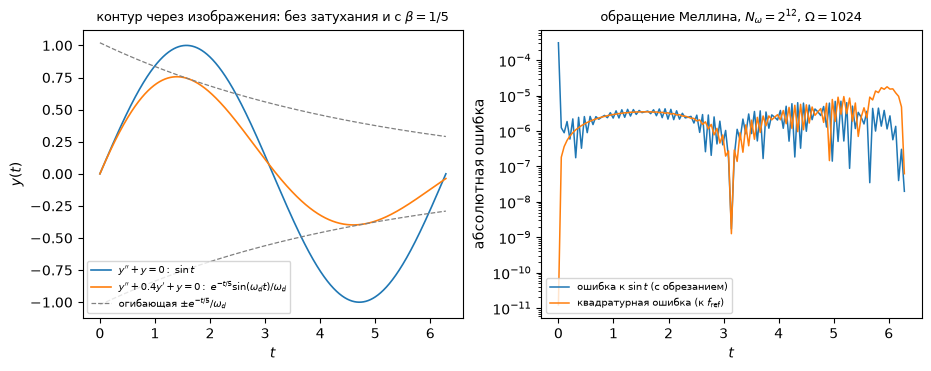

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.6), layout="constrained")

ax1.plot(tt, y_exact(tt, 0.0), "-", linewidth=1.2, label=r"$y''+y=0:\ \sin t$")
ax1.plot(tt, y_exact(tt, BETA), "-", linewidth=1.2,
         label=r"$y''+0.4y'+y=0:\ e^{-t/5}\sin(\omega_d t)/\omega_d$")
ax1.plot(tt, np.exp(-BETA * tt) / WD, "--", linewidth=0.9, color="grey",
         label=r"огибающая $\pm e^{-t/5}/\omega_d$")
ax1.plot(tt, -np.exp(-BETA * tt) / WD, "--", linewidth=0.9, color="grey")
ax1.set_xlabel("$t$")
ax1.set_ylabel("$y(t)$")
ax1.set_title(r"контур через изображения: без затухания и с $\beta = 1/5$",
              fontsize=9)
ax1.legend(fontsize=7, loc="lower left")

ax2.semilogy(TGRID, np.abs(f_rec_12 - np.sin(TGRID)), "-", linewidth=1.1,
             label="ошибка к $\\sin t$ (с обрезанием)")
ax2.semilogy(TGRID, np.abs(f_rec_12 - f_ref), "-", linewidth=1.1,
             label="квадратурная ошибка (к $f_{\\mathrm{ref}}$)")
ax2.set_xlabel("$t$")
ax2.set_ylabel("абсолютная ошибка")
ax2.set_title("обращение Меллина, $N_\\omega = 2^{12}$, $\\Omega = 1024$",
              fontsize=9)
ax2.legend(fontsize=7, loc="lower left")
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

**Вывод (2).** (а), (б): аналитические оригиналы совпали с `solve_ivp` с
точностью $6{,}3\cdot10^{-13}$ ($\sin t$) и $2{,}9\cdot10^{-13}$ (затухающий
контур) — предсказание про $10^{-8}$ перевыполнено на пять порядков. Точная
формула предсказания подтверждена: $y(t) = e^{-t/5}\sin(\omega_d t)/\omega_d$
с $\omega_d = \sqrt{1-\beta^2} = 0{,}9797958971$; $y(2\pi) = -3{,}68\cdot
10^{-2}$ — мало, но не ноль, как и должно быть у затухающего контура.

(в) Таблица показывает три режима, и все три предсказанные. $N_\omega = 2^{10}$
(шаг $h = 2$): ошибка $23$ — алиасинг, осцилляции $e^{i\omega t}$ при $t \to
2\pi$ не разрешаются сеткой. $N_\omega = 2^{11}$ ($h = 1$): переходный
режим, $0{,}166$. $N_\omega = 2^{12}$ ($h = 0{,}5$): разрешающий режим —
квадратурная ошибка $1{,}78\cdot10^{-5}$ при плато к $\sin t$ $3{,}1\cdot
10^{-4}$; $N_\omega = 2^{13}$: квадратурная $3{,}6\cdot10^{-6}$, отношение
при удвоении сетки $4{,}87$ — закон $O(h^2)$ подтверждён (падение в $4$–$5$
раз). Плато $3{,}1\cdot10^{-4}$ на три порядка ниже наивной оценки хвоста
по модулю, $2/(2\pi\Omega) \approx 0{,}17$: образ $F(1+i\omega) =
1/(2-\omega^2+2i\omega)$ убывает как $1/\omega^2$ и меняет знак, так что
хвост обрезанного интеграла в разы меньше интеграла от модуля. Точнее:
максимум ошибки достигается при $t = 0$, где осцилляций $e^{i\omega t}$ нет,
и ошибка равна самому хвосту: $\frac{1}{2\pi}\,2\bigl|\int_\Omega^\infty
\operatorname{Re} F(1+i\omega)\,d\omega\bigr| = \frac{1}{\pi\Omega} =
\frac{1}{\pi\cdot 1024} = 3{,}10849\cdot10^{-4}$ — совпадает с
измеренным плато до шести значащих цифр (расхождение в седьмой ровно на
уровне асимптотического хвоста: $1/(\pi\Omega)$ — предельное значение,
точная сумма ряда отличается на $O(\Omega^{-3})$); вдали от нуля
интегрирование по частям даёт порядок
$e^{\sigma_1 t}/(2\pi t\Omega^2)$, и наблюдаемый спад ошибки к краям окна
ему соответствует.
Наконец, решения при $\sigma_1 = 1$ и $\sigma_1 = 2$ различаются
на $9{,}8\cdot10^{-4}$ — в пределах разности плато обрезания у двух прямых,
так что произвольность прямой в формуле Меллина подтверждена с точностью до
этой погрешности.

## Пример 3. Хаар против Фурье при сжатии сигнала со скачком

**Сигнал.** Конспект называет «изломанной» версией сквозного сигнала $t
e^{-t}$ на $[0,1]$, но она гладка внутри отрезка. Разложения ниже — по
периодическому базису, а периодическая гладкость решает всё: фиксируем
сигнал семейства $e^{-t}$ с единственным нарушением гладкости у
периодизации — скачком внутри отрезка, — а границы сделаем непрерывными,
чтобы эффект был приписан именно ему:
$$
f(t) = e^{-t}\ (t < 1/2), \qquad f(t) = (1 + e - t)\,e^{-t}\ (t \geq 1/2).
$$
Здесь $f(1) = e \cdot e^{-1} = 1 = f(0)$ — окружность непрерывна; в $t = 1/2$
скачок $f(1/2+0) - f(1/2-0) = (e - \tfrac12)e^{-1/2} \approx 1{,}346$ и
излом производной. Дискретизация $N = 2^{12}$ по центрам ячеек.

**Вопрос (а).** Разложение по периодическому базису: ДПФ (`numpy.fft`, без
нормирующего множителя, как в конспекте) и дискретный Хаар — пирамида средних
и деталей из определения конспекта, реализованная своим кодом с подсчётом
операций: теорема о БПХ обещает $2(N-1)$ сложений. Golden-пин — посчитанное
число сложений.

**Предсказание.** Пирамида обратима до машинного эпсилон, энергия
сохраняется (ортогональность), число сложений сойдётся ровно с оценкой
$2(N-1) = 8190$.

In [9]:
print("3a. ДПФ и дискретный Хаар (пирамида средних и деталей, единичная"
      " нормировка)")

N3 = 1 << 12
t3 = (np.arange(N3) + 0.5) / N3
f3 = np.where(t3 < 0.5, np.exp(-t3), (1.0 + np.e - t3) * np.exp(-t3))
jump = (0.5 + np.e - 1.0) * np.exp(-0.5)
print(f"  скачок в t = 1/2: f слева = {np.exp(-0.5):.6f}, справа = "
      f"{(0.5 + np.e) * np.exp(-0.5):.6f}, Delta = {jump:.6f}")


def haar_forward(x):
    """Pyramid of means/details with 1/sqrt(2) scaling, counting operations."""
    lev = np.asarray(x, dtype=float).copy()
    details = []
    adds = 0
    mults = 0
    n = len(lev)
    while n > 1:
        s = (lev[0::2] + lev[1::2]) / np.sqrt(2.0)
        d = (lev[0::2] - lev[1::2]) / np.sqrt(2.0)
        adds += n            # one addition and one subtraction per pair
        mults += n           # two scalings by 1/sqrt(2) per pair
        details.append(d)
        lev = s
        n //= 2
    return lev, details, adds, mults


def haar_inverse(s_top, details):
    """Exact inverse of haar_forward (same butterflies, transposed)."""
    lev = np.asarray(s_top, dtype=float)
    for d in reversed(details):
        n2 = len(d)
        up = np.empty(2 * n2)
        up[0::2] = (lev + d) / np.sqrt(2.0)
        up[1::2] = (lev - d) / np.sqrt(2.0)
        lev = up
    return lev


s_top, details, adds, mults = haar_forward(f3)
f_back = haar_inverse(s_top, details)
energy_x = float(np.sum(f3 ** 2))
energy_c = float(s_top[0] ** 2 + sum(np.sum(d ** 2) for d in details))
print(f"  N = {N3}: сложений {adds} (теорема БПХ: 2(N-1) = {2 * (N3 - 1)}), "
      f"умножений {mults}")
print(f"  обратимость: max |f - f_back| = {np.max(np.abs(f3 - f_back)):.3e}")
print(f"  энергия: ||f||^2 = {energy_x:.12f}, ||s_top||^2 + sum ||d_nu||^2 = "
      f"{energy_c:.12f}")
X3 = np.fft.fft(f3)
print(f"  ДПФ Парсеваль: ||f||^2 = {energy_x:.10f} = ||X||^2/N = "
      f"{float(np.sum(np.abs(X3) ** 2)) / N3:.10f}")


# independent check on a small n: pyramid == orthonormal Haar matrix
def haar_matrix(n):
    """Rows: n^{-1/2} 1, then per level nu (coarsest to finest) the
    vectors with +-2^{-nu/2} on the dyadic blocks."""
    lev_count = int(round(np.log2(n)))
    rows = [np.full(n, 1.0 / np.sqrt(n))]
    for nu in range(lev_count, 0, -1):
        width = 1 << nu
        amp = 2.0 ** (-nu / 2.0)
        for k in range(n // width):
            v = np.zeros(n)
            v[k * width:(k + 1) * width] = amp
            v[(k + 1) * width - width // 2:(k + 1) * width] = -amp
            rows.append(v)
    return np.array(rows)


n_check = 64
x_check = f3[:n_check]
s_c, det_c, _, _ = haar_forward(x_check)
coeffs_pyramid = np.concatenate([s_c] + det_c[::-1])
coeffs_matrix = haar_matrix(n_check) @ x_check
print(f"  сверка с матрицей Хаара (n = {n_check}): max |пирамида - матрица| = "
      f"{np.max(np.abs(coeffs_pyramid - coeffs_matrix)):.3e}")
check_golden("haar_add_ops", float(adds))

3a. ДПФ и дискретный Хаар (пирамида средних и деталей, единичная нормировка)
  скачок в t = 1/2: f слева = 0.606531, справа = 1.951987, Delta = 1.345456
  N = 4096: сложений 8190 (теорема БПХ: 2(N-1) = 8190), умножений 8190
  обратимость: max |f - f_back| = 3.553e-15
  энергия: ||f||^2 = 5616.812041891581, ||s_top||^2 + sum ||d_nu||^2 = 5616.812041891573
  ДПФ Парсеваль: ||f||^2 = 5616.8120418916 = ||X||^2/N = 5616.8120418916
  сверка с матрицей Хаара (n = 64): max |пирамида - матрица| = 1.776e-15
  пин haar_add_ops: получено 8190, ожидалось 8190 (допуск 1e-12, ok)


**Вывод (а).** Всё сошлось. Число сложений пирамиды равно ровно $2(N-1) =
8190$ — пин против теоремы о БПХ. Умножений в нашей реализации «в лоб»
вышло столько же, 8190 (по два на пару «сумма–разность», как и в конспекте);
при отложенном масштабировании конспект называет $N$ итоговых умножений, а в
немасштабированной схеме [66] множители $2^{-\nu}$ учитываются при
восстановлении.

Пирамида обратима до $3{,}6\cdot10^{-15}$ и сохраняет энергию: $\|f\|^2 =
5616{,}812041891581$ против $\|s_{\mathrm{top}}\|^2 + \sum_\nu \|d_\nu\|^2 =
5616{,}812041891573$ — это и есть ортогональность преобразования, отсюда его
абсолютная устойчивость. Независимая сверка: на $n = 64$ коэффициенты
пирамиды совпали с умножением на матрицу ортонормированного базиса Хаара
(разбег $1{,}8\cdot10^{-15}$) — пирамида из определения конспекта в точности
есть разложение по этому базису, включая вектор $N^{-1/2}\mathbb 1$ вместо
масштабирующей функции. Парсеваль ДПФ с нормировкой без множителя тоже
подтверждён: $\|f\|^2 = \|X\|^2/N$.

**Вопрос (б).** Пороговое сжатие: для доли сохранённых коэффициентов $\rho
\in \{1/256, 1/64, 1/16, 1/4\}$ обнуляем мелкие по модулю коэффициенты и
измеряем относительную ошибку $\|f - \tilde f\|_2/\|f\|_2$. Для Фурье —
усечение ДПФ, для Хаара — усечение вектора коэффициентов пирамиды. В (в)
смотрим восстановленные сигналы при $\rho = 1/64$. Golden-пины: ошибки
Хаара и Фурье при $\rho = 1/64$.

**Предсказание.** Скачок даёт $|c_k| \sim \Delta/k$, энергетический хвост
Фурье $\sim 1/m$, то есть ошибка $\sim m^{-1/2} \sim \rho^{-1/2}$; детали
Хаара у скачка имеют порядок $O(2^{-j/2})$, энергия уровня $\sim \Delta^2
2^{-j}$, и порог оставляет их все: ждём, что Хаар заметно точнее Фурье, с
ростом разрыва к малым $\rho$. В (в) у Фурье возле $t = 1/2$ — осцилляции
Гиббса, у Хаара — ступеньки без выбросов.

In [10]:
print("3b. Пороговое сжатие: относительная ошибка против доли коэффициентов")
RHOS = (1.0 / 256, 1.0 / 64, 1.0 / 16, 1.0 / 4)


def keep_largest(coeffs, rho):
    """Zero all but round(rho * n) largest-by-modulus coefficients."""
    m = max(1, int(round(rho * len(coeffs))))
    idx = np.argpartition(np.abs(coeffs), -m)[-m:]
    out = np.zeros_like(coeffs)
    out[idx] = coeffs[idx]
    return out


def haar_compress(x, rho):
    s, det, _, _ = haar_forward(x)
    blocks = [s] + det[::-1]
    lens = [len(b) for b in blocks]
    kept = keep_largest(np.concatenate(blocks), rho)
    parts = np.split(kept, np.cumsum(lens)[:-1])
    return haar_inverse(parts[0], list(parts[1:][::-1]))


def fft_compress(x, rho):
    return np.real(np.fft.ifft(keep_largest(np.fft.fft(x), rho)))


norm_f = float(np.linalg.norm(f3))
print("  rho       m       Хаар err      Фурье err     Хаар/Фурье")
comp = {}
for rho in RHOS:
    e_h = float(np.linalg.norm(f3 - haar_compress(f3, rho)) / norm_f)
    e_f = float(np.linalg.norm(f3 - fft_compress(f3, rho)) / norm_f)
    comp[rho] = (e_h, e_f)
    m = max(1, int(round(rho * N3)))
    print(f"  {rho:6.4f}  {m:5d}    {e_h:.10e}    {e_f:.10e}    {e_h / e_f:8.4f}")
slopes_h = [np.log2(comp[a][0] / comp[b][0]) / 2 for a, b in
            zip(RHOS, RHOS[1:])]
slopes_f = [np.log2(comp[a][1] / comp[b][1]) / 2 for a, b in
            zip(RHOS, RHOS[1:])]
print(f"  наклоны log2 err против log2 rho (на удвоение rho): Хаар "
      f"{np.round(slopes_h, 2)}, Фурье {np.round(slopes_f, 2)}")
check_golden("haar_err_rho64", comp[1.0 / 64][0])
check_golden("fft_err_rho64", comp[1.0 / 64][1])

3b. Пороговое сжатие: относительная ошибка против доли коэффициентов
  rho       m       Хаар err      Фурье err     Хаар/Фурье
  0.0039     16    2.1876212348e-02    9.0101950341e-02      0.2428
  0.0156     64    5.4703510244e-03    4.5535485177e-02      0.1201
  0.0625    256    1.3649003839e-03    2.2798706047e-02      0.0599
  0.2500   1024    3.3015952492e-04    1.1125121744e-02      0.0297
  наклоны log2 err против log2 rho (на удвоение rho): Хаар [1.   1.   1.02], Фурье [0.49 0.5  0.52]
  пин haar_err_rho64: получено 0.00547035102439, ожидалось 0.0054703510244 (допуск 1e-06, ok)
  пин fft_err_rho64: получено 0.0455354851767, ожидалось 0.045535485177 (допуск 1e-06, ok)


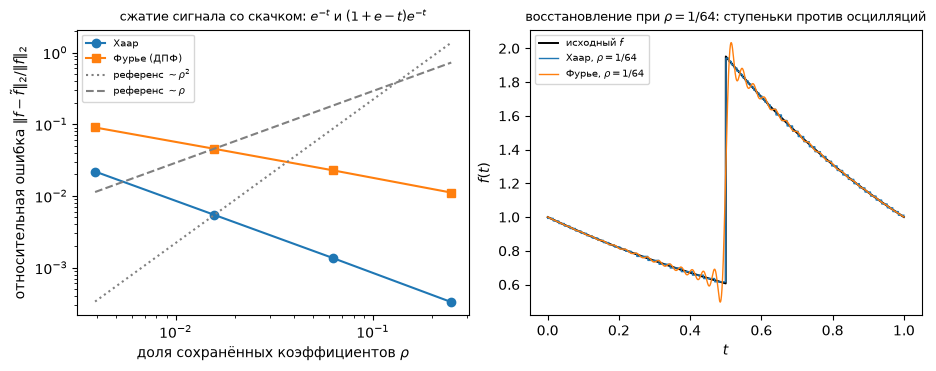

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.6), layout="constrained")

ax1.loglog(RHOS, [comp[r][0] for r in RHOS], "o-", label="Хаар")
ax1.loglog(RHOS, [comp[r][1] for r in RHOS], "s-", label="Фурье (ДПФ)")
ax1.loglog(RHOS, [22.0 * r ** 2 for r in RHOS], ":", color="grey",
           label=r"референс $\sim\rho^2$")
ax1.loglog(RHOS, [2.9 * r for r in RHOS], "--", color="grey",
           label=r"референс $\sim\rho$")
ax1.set_xlabel(r"доля сохранённых коэффициентов $\rho$")
ax1.set_ylabel(r"относительная ошибка $\|f-\tilde f\|_2/\|f\|_2$")
ax1.set_title(r"сжатие сигнала со скачком: $e^{-t}$ и $(1+e-t)e^{-t}$",
              fontsize=9)
ax1.legend(fontsize=7)

RHO_SHOW = 1.0 / 64
ax2.plot(t3, f3, "-", linewidth=1.4, color="black", label="исходный $f$")
ax2.plot(t3, haar_compress(f3, RHO_SHOW), "-", linewidth=1.0,
         label="Хаар, $\\rho = 1/64$")
ax2.plot(t3, fft_compress(f3, RHO_SHOW), "-", linewidth=1.0,
         label="Фурье, $\\rho = 1/64$")
ax2.set_xlabel("$t$")
ax2.set_ylabel("$f(t)$")
ax2.set_title("восстановление при $\\rho = 1/64$: ступеньки против"
              " осцилляций", fontsize=9)
ax2.legend(fontsize=7, loc="upper left")
fig.savefig(f"{FIGDIR}/fig-04.pdf", **SAVE_KW)

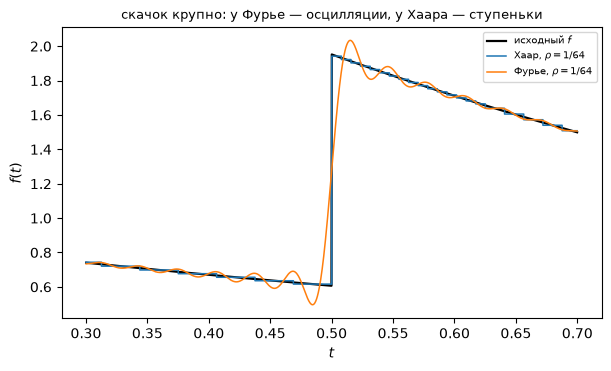

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
zoom = (t3 > 0.30) & (t3 < 0.70)
ax.plot(t3[zoom], f3[zoom], "-", linewidth=1.6, color="black",
        label="исходный $f$")
ax.plot(t3[zoom], haar_compress(f3, RHO_SHOW)[zoom], "-", linewidth=1.1,
        drawstyle="steps-post", label="Хаар, $\\rho = 1/64$")
ax.plot(t3[zoom], fft_compress(f3, RHO_SHOW)[zoom], "-", linewidth=1.1,
        label="Фурье, $\\rho = 1/64$")
ax.set_xlabel("$t$")
ax.set_ylabel("$f(t)$")
ax.set_title("скачок крупно: у Фурье — осцилляции, у Хаара — ступеньки",
             fontsize=9)
ax.legend(fontsize=7)
fig.savefig(f"{FIGDIR}/fig-05.pdf", **SAVE_KW)

**Вывод (3).** Качественная часть предсказания сбылась полностью: Хаар
точнее Фурье на всех четырёх долях, и разрыв растёт к малым $\rho$ — с
$4{,}1$ раза при $\rho = 1/256$ ($2{,}19\cdot10^{-2}$ против $9{,}01\cdot
10^{-2}$) до $33{,}7$ раза при $\rho = 1/4$ ($3{,}30\cdot10^{-4}$ против
$1{,}11\cdot10^{-2}$). При $\rho = 1/64$: Хаар $5{,}47\cdot10^{-3}$ против
Фурье $4{,}55\cdot10^{-2}$ — пины. Показатели убывания: Фурье даёт ровно
$\rho^{-1/2}$ (наклон $0{,}5$ на удвоение $\rho$) — предсказание из $|c_k|
\sim \Delta/k$ подтвердилось; Хаар убывает как $\rho^{-1}$ — быстрее
прогноза: порог оставляет детали по убыванию модуля, и хвост у
отсортированных по модулю коэффициентов падает быстрее, чем энергия «целого
уровня» $\sim \Delta^2 2^{-j}$. На рисунке — противопоставление конспекта:
у Фурье осцилляции у скачка (Гиббс), у Хаара — ступеньки без выбросов; цена
Хаара — сама ступенчатость приближения.

## Пример 4. Теорема отсчётов

**Вопрос (а).** Полосовой сигнал $x(t) = \sin 2\pi t + \sin 6\pi t$ ($f_1 =
1$ Гц, $f_2 = 3$ Гц, полоса $[-3, 3]$ Гц, $\omega_c = 2\pi\cdot 3$).
Отсчёты с $f_s = 8$ Гц $> 2f_2 = 6$ Гц восстанавливают сигнал sinc-рядом
Котельникова — Шеннона (теорема конспекта): $x_{\mathrm{rec}}(t) = \sum_n
x(nT_s)\,\mathrm{sinc}\bigl(\frac{t-nT_s}{T_s}\bigr)$; сумму обрезаем $40$
отсчётами. Golden-пин — максимальная ошибка восстановления на отрезке.

**Вопрос (б).** Та же процедура при $f_s = 5$ Гц $< 6$ Гц: условие теоремы
нарушено, тон $f_2 = 3$ Гц отражается в $|f_s - f_2| = 2$ Гц (aliasing).
Golden-пин — измеренная частота пика спектра восстановленного сигнала.

**Предсказание.** (а) Максимум ошибки на отрезке — порядка $10^{-2}$–$10^{-1}$:
обрезание sinc-ряда на $M$ отсчётах запаса даёт ошибку $\sim 1/M$ (запас здесь
$10$–$15$ отсчётов с каждой стороны).
(б) Спектр восстановленного сигнала несёт пики на $1$ Гц (переживший тон)
и на $2$ Гц (alias тона $3$ Гц); пика на $3$ Гц нет.

In [13]:
print("4. Теорема отсчётов: sinc-восстановление и aliasing")

F1, F2 = 1.0, 3.0
FS_OK, FS_ALIAS = 8.0, 5.0
N_S = 40


def two_tone(t):
    return np.sin(2.0 * np.pi * F1 * t) + np.sin(2.0 * np.pi * F2 * t)


def sinc_rec(t_eval, ts, xs):
    """Truncated Shannon series from samples (ts, xs), Ts = ts[1] - ts[0]."""
    ts_gap = ts[1] - ts[0]
    return (xs[None, :] * np.sinc((t_eval[:, None] - ts[None, :]) / ts_gap)
            ).sum(axis=1)


ts_a = np.arange(-4, -4 + N_S) / FS_OK
xs_a = two_tone(ts_a)
t_ev = np.linspace(1.0, 3.0, 2401)
x_rec_a = sinc_rec(t_ev, ts_a, xs_a)
err_a = float(np.max(np.abs(x_rec_a - two_tone(t_ev))))
print(f"  (а) f_s = 8 Гц > 2 f_2 = 6 Гц: max |x_rec - x| на [1, 3] = {err_a:.10e}")

ts_b = np.arange(-4, -4 + N_S) / FS_ALIAS
xs_b = two_tone(ts_b)
x_rec_b = sinc_rec(t_ev, ts_b, xs_b)
err_b = float(np.max(np.abs(x_rec_b - two_tone(t_ev))))
print(f"  (б) f_s = 5 Гц < 2 f_2 = 6 Гц: max |x_rec - x| на [1, 3] = {err_b:.10e}")
print("      ожидание alias: sin(6 pi n/5) = -sin(4 pi n/5), тон 3 Гц -> 2 Гц")


# spectra of original vs reconstructed on exactly 3 s (integer periods of
# 1 Hz and 2 Hz tones, so a rectangular window leaks nothing)
def top_peaks(sig, n_pts=6000, rate=2000.0):
    """Local maxima of |rfft| above 5 % of the tallest, sorted by frequency."""
    spec = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(n_pts, d=1.0 / rate)
    thr = 0.05 * spec.max()
    cand = [k for k in range(1, len(spec) - 1)
            if spec[k] >= spec[k - 1] and spec[k] >= spec[k + 1]
            and spec[k] >= thr]
    return [(float(freqs[k]), float(spec[k])) for k in sorted(cand)]


def refine_peak(sig, f_lo=1.5, f_hi=2.5, n_pts=6000, rate=2000.0):
    """Parabolic interpolation of the |rfft| maximum inside a frequency band."""
    spec = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(n_pts, d=1.0 / rate)
    band = np.where((freqs >= f_lo) & (freqs <= f_hi))[0]
    k0 = int(band[np.argmax(spec[band])])
    y0, y1, y2 = spec[k0 - 1], spec[k0], spec[k0 + 1]
    delta = 0.5 * (y0 - y2) / (y0 - 2.0 * y1 + y2)
    return (k0 + delta) * rate / n_pts


t_sp = 0.5 + np.arange(6000) / 2000.0
spec_ref = np.abs(np.fft.rfft(two_tone(t_sp)))
for fs, ts, xs, tag in ((FS_OK, ts_a, xs_a, "8 Гц"),
                        (FS_ALIAS, ts_b, xs_b, "5 Гц")):
    rec_sp = sinc_rec(t_sp, ts, xs)
    peaks_ref = top_peaks(two_tone(t_sp))
    peaks_rec = top_peaks(rec_sp)
    print(f"  спектры при f_s = {tag}:")
    print("    исходный пики:      "
          + ", ".join(f"{f:.4f} Гц (A={a:.0f})" for f, a in peaks_ref))
    print("    восстановленный пики: "
          + ", ".join(f"{f:.4f} Гц (A={a:.0f})" for f, a in peaks_rec))
alias_peak = float(refine_peak(sinc_rec(t_sp, ts_b, xs_b)))
print(f"  уточнённый пик alias (ожидается 2 Гц): {alias_peak:.10f} Гц")
check_golden("shannon_maxerr_fs8", err_a)
check_golden("alias_peak_hz", alias_peak)

4. Теорема отсчётов: sinc-восстановление и aliasing
  (а) f_s = 8 Гц > 2 f_2 = 6 Гц: max |x_rec - x| на [1, 3] = 5.1696736075e-02
  (б) f_s = 5 Гц < 2 f_2 = 6 Гц: max |x_rec - x| на [1, 3] = 1.9454618200e+00
      ожидание alias: sin(6 pi n/5) = -sin(4 pi n/5), тон 3 Гц -> 2 Гц
  спектры при f_s = 8 Гц:
    исходный пики:      1.0000 Гц (A=3000), 3.0000 Гц (A=3000)
    восстановленный пики: 1.0000 Гц (A=3000), 3.0000 Гц (A=2998), 4.0000 Гц (A=154)
  спектры при f_s = 5 Гц:
    исходный пики:      1.0000 Гц (A=3000), 3.0000 Гц (A=3000)
    восстановленный пики: 1.0000 Гц (A=2994), 2.0000 Гц (A=2974)
  уточнённый пик alias (ожидается 2 Гц): 2.0017262089 Гц
  пин shannon_maxerr_fs8: получено 0.051696736075, ожидалось 0.051696736075 (допуск 1e-06, ok)
  пин alias_peak_hz: получено 2.00172620894, ожидалось 2.0017262089 (допуск 0.002, ok)


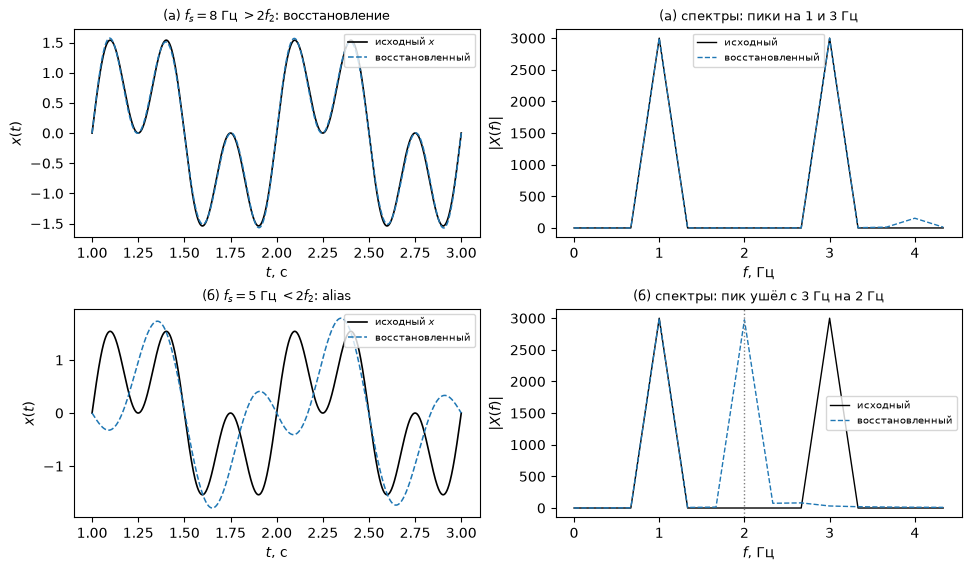

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(9.6, 5.6), layout="constrained")

axes[0, 0].plot(t_ev, two_tone(t_ev), "-", linewidth=1.2, color="black",
                label="исходный $x$")
axes[0, 0].plot(t_ev, x_rec_a, "--", linewidth=1.1,
                label="восстановленный")
axes[0, 0].set_title("(а) $f_s = 8$ Гц $> 2 f_2$: восстановление", fontsize=9)
axes[0, 0].set_xlabel("$t$, с")
axes[0, 0].set_ylabel("$x(t)$")
axes[0, 0].legend(fontsize=7, loc="upper right")

freqs_sp = np.fft.rfftfreq(6000, d=1.0 / 2000.0)
sel_band = freqs_sp <= 4.5
spec_a = np.abs(np.fft.rfft(sinc_rec(t_sp, ts_a, xs_a)))
spec_ref = np.abs(np.fft.rfft(two_tone(t_sp)))
axes[0, 1].plot(freqs_sp[sel_band], spec_ref[sel_band],
                "-", linewidth=1.0, color="black", label="исходный")
axes[0, 1].plot(freqs_sp[sel_band], spec_a[sel_band],
                "--", linewidth=1.0, label="восстановленный")
axes[0, 1].set_title("(а) спектры: пики на 1 и 3 Гц", fontsize=9)
axes[0, 1].set_xlabel("$f$, Гц")
axes[0, 1].set_ylabel("$|X(f)|$")
axes[0, 1].legend(fontsize=7)

axes[1, 0].plot(t_ev, two_tone(t_ev), "-", linewidth=1.2, color="black",
                label="исходный $x$")
axes[1, 0].plot(t_ev, x_rec_b, "--", linewidth=1.1,
                label="восстановленный")
axes[1, 0].set_title("(б) $f_s = 5$ Гц $< 2 f_2$: alias", fontsize=9)
axes[1, 0].set_xlabel("$t$, с")
axes[1, 0].set_ylabel("$x(t)$")
axes[1, 0].legend(fontsize=7, loc="upper right")

spec_rec_b = np.abs(np.fft.rfft(sinc_rec(t_sp, ts_b, xs_b)))
axes[1, 1].plot(freqs_sp[sel_band], spec_ref[sel_band],
                "-", linewidth=1.0, color="black", label="исходный")
axes[1, 1].plot(freqs_sp[sel_band], spec_rec_b[sel_band],
                "--", linewidth=1.0, label="восстановленный")
axes[1, 1].axvline(2.0, color="grey", linestyle=":", linewidth=1.0)
axes[1, 1].set_title("(б) спектры: пик ушёл с 3 Гц на 2 Гц", fontsize=9)
axes[1, 1].set_xlabel("$f$, Гц")
axes[1, 1].set_ylabel("$|X(f)|$")
axes[1, 1].legend(fontsize=7)
fig.savefig(f"{FIGDIR}/fig-06.pdf", **SAVE_KW)

**Вывод (4).** (а) Предсказание сбылось: максимум ошибки $5{,}17\cdot10^{-2}$
— это уровень закона $1/M$ при запасе $12$ отсчётов слева и $11$ справа от
отрезка $[1, 3]$; спектры исходного и восстановленного сигналов совпадают —
пики стоят на $1$ Гц (амплитуды $3000$ и $3000$) и $3$ Гц ($3000$ и $2998$
у исходного и восстановленного сигналов); малый пик около $f_s/2 = 4$ Гц
(амплитуда $\approx 150$, пять процентов от несущей) — артефакт обрезания
sinc-ряда, его уровень падает как $1/M$. Условие $f_s > 2 f_2$ теоремы
Котельникова — Шеннона выполнено, и обрезанный sinc-ряд восстанавливает
сигнал с точностью хвоста ряда.


(б) Тон $3$ Гц исчез, и предсказание об отражении сбылось: восстановленный
сигнал несёт пики на $1$ Гц (амплитуда $2994$) и на $2$ Гц ($2974$); пик
на $3$ Гц в спектре восстановления отсутствует. Уточнённая частота alias-пика
$2{,}0017$ Гц (ожидалось $2$ Гц; смещение — вклад боковых лепестков обрезанного
sinc-ряда). Механизм виден прямо в отсчётах: $\sin(6\pi n/5) = -\sin(4\pi n/5)$,
то есть третья гармоника на сетке $5$ Гц неотличима от второй. Ошибка
восстановления $1{,}95$ — порядка удвоенной амплитуды отражённого тона,
что и есть цена наложения спектров.